<span style="font-family: Times New Roman; font-size: 30px; font-weight: bold;">
A Brain Network Exploration Through Random Network Models
</span>

<br> <!-- Agrega un salto de línea -->

<span style="font-family: Times New Roman; font-size: 24px;">
Advanced Data Analysis (PHYS 605) Final Project.
</span>

<br> <!-- Agrega un salto de línea -->

<span style="font-family: Times New Roman; font-size: 20px; font-weight: italics;">
Random Network vs Real Brain Network
</span>

## Reproducibility note

This notebook contains exploratory analyses of a structural connectome.
The source edge list is **not included** in the repository; obtain it from
the Network Data Repository before running the real-network cells.
Random examples use a fixed seed. Figures and outputs for revised cells
have been cleared so they are not mistaken for newly reproduced results.
The analysis below does **not** establish a scale-free or small-world network.


In [ ]:
# Libraries and reproducibility
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import binom, poisson
import powerlaw

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)


<span style="font-family: Times New Roman; font-size: 24px;">
Generating and studying the G(N,p) Random Network
</span>

<br> <!-- Agrega un salto de línea -->

<span style="font-family: Times New Roman; font-size: 20px; font-weight: italics;">
The random network that we are going to generate is known as the model G(N,p), where you have a fixed value of the couple of nodes and you add the edges following a probability of p≤1 of having an edge in an specific couple of nodes. G(N, p) model in which the probability of having a link between two nodes is equal to p < 1.
</span>
    
<br> <!-- Agrega un salto de línea -->

In [ ]:
# Generate an undirected Erdős–Rényi G(N, p) graph.
# Use NetworkX's efficient implementation for large sparse graphs.
def random_Network(N, p, seed=None):
    return nx.fast_gnp_random_graph(N, p, seed=seed)

N = 100
p = 0.5
G = random_Network(N, p, seed=RANDOM_SEED)
nx.draw(G, node_size=80, node_color="#FF69B4", node_shape="o")
plt.show()


In [ ]:
N = 100
p = 0.5
G = random_Network(N, p, seed=RANDOM_SEED)
rshort_path_length = nx.average_shortest_path_length(G)
print("Average shortest path length for the 100-node random example:", rshort_path_length)
# This value is NOT a small-world test for the brain connectome.


In [ ]:
# Sparse Erdős–Rényi comparison with the approximate size and density
# of the sampled brain network. Graph generation does not imply small-worldness.
N1 = 9119
p1 = 0.00184
G1 = random_Network(N1, p1, seed=RANDOM_SEED)


<span style="font-family: Times New Roman; font-size: 20px; font-weight: italics;">
The degree distribution for an Erdos-Renyi random Network can be appproached to a Binomial distribution...
</span>
    
<br> <!-- Agrega un salto de línea -->

In [ ]:
#Binomial degree distribution
sns.set() #Style
#Create a figure and select its size
plt.figure(figsize=(10, 10))

runnings = 100

#Creating an array of zeros 
Y = np.zeros(N-1)


for i in range(runnings): #Multiple runnings to create the ensemble
    
    #Generating the random Network
    G = random_Network(N, p, seed=int(rng.integers(0, 2**32 - 1))) 
    
    #[dict(G.degree)[i] for i in G]: We have a dictionary that contains the degrees for a node i
    #bins = range(N): The degree can only go from 0 to N-1
    #density = True: Without this we will only have the number of nodes with k degree,
    #but when we add it we normalize the histogram transforming it into a probability dist.
    #Thus, with this we change it into a probability distribution Pk=Nk/N
    y, x = np.histogram([dict(G.degree)[i] for i in G], bins = range(N), density = True)
    
    Y += y #Summing all the histograms generated in every running
    
Y = Y/runnings #Diviing them over the number of runnings

#For the histogram
sns.barplot(x=x[:-1], y=Y, color='#FF69B4', label='Pk')

#Comparing our distribution to verify if it fits with the Biniomial Probability Mass Function
plt.plot(x[:-1], binom.pmf(x[:-1],N-1,p), 'black', label = 'Binomial')

#Title and labels of the plot              
plt.xlabel('k', size = 20)
font_name = "Times New Roman" 
#plt.title('Random Network, N = %i, p = %1.2f' %(N,p), size = 20)
plt.xlabel('Degree Distribution', fontsize=20, fontname=font_name)
plt.ylabel('Probability Distribution', fontsize=20, fontname=font_name)
plt.title('Random Network, N = %i, p = %1.2f' %(N,p), fontsize=24, fontname=font_name)
plt.legend()

selected_ticks = np.arange(min(x[:-1]), max(x[:-1])+1, 10)  #Every ten values
plt.xticks(selected_ticks)

#Show the plot     
plt.show()

<br> <!-- Agrega un salto de línea -->
<span style="font-family: Times New Roman; font-size: 20px; font-weight: italics;">
The probability distribution could be appproach to a Poisson distribution when....
</span>
    
<br> <!-- Agrega un salto de línea -->

Text(0, 0.5, 'Probability Mass Function (k)')

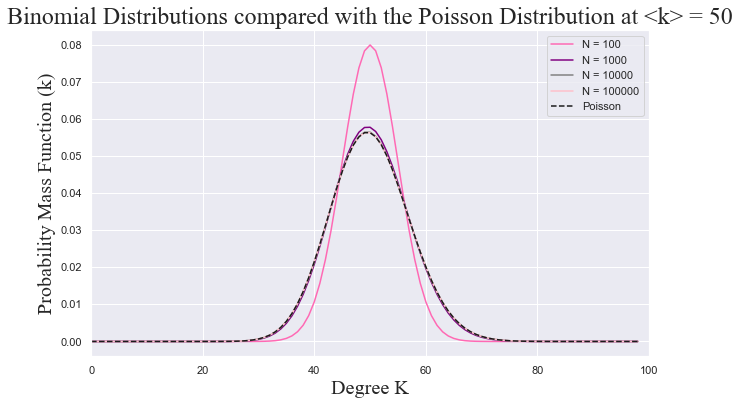

In [6]:
#Different binomial distributions to approach into a Poission

k = 50 #Choosing a value of k less than the length of the Network
x = np.arange(100)

sns.set()
#Create a figure and select its size
plt.figure(figsize=(10, 6))

#Choosing the colors I will use
colores = ['#FF69B4', 'purple', 'grey', 'pink']

#We will select 4 N´s of 4 magnitud orders
for i,N in enumerate([10**2, 10**3, 10**4, 10**5]):
    
    p = k/(N-1) #probability of linking

    plt.plot(x[:-1],binom.pmf(x[:-1], N-1, p), label = 'N = '+str(N), color=colores[i]) #Plot binomials

    
#Limiting the x-axis values
plt.xlim([0,100])

#Plotting the Poisson distribution
plt.plot(x[:-1], poisson.pmf(x[:-1], 50), 'k--', label = 'Poisson')

#Selecting Times new Roman as font for the plot writtens
font_name = "Times New Roman" 

#Plotting
plt.legend()
plt.title('Binomial Distributions compared with the Poisson Distribution at <k> = 50', fontsize=24, fontname=font_name)
plt.xlabel('Degree K', fontsize=20, fontname=font_name)
plt.ylabel('Probability Mass Function (k)', fontsize=20, fontname=font_name)

<br> <!-- Agrega un salto de línea -->

<span style="font-family: Times New Roman; font-size: 20px; font-weight: italics;">
Now let´s see what happens with the clustering coefficients....
</span>
    
<br> <!-- Agrega un salto de línea -->

In [ ]:
#Showing how the clustering coefficients matches with the linking probability

#Giving the same properties than before to our random Network
N=100 
p=.5

#Generating the Network
G = random_Network(N, p, seed=RANDOM_SEED)

#Computing the average clustering coefficient
C = nx.average_clustering(G)

#Showing values
print('The average clustering coefficient is:\n', C)
print('The probability of linking is:\n', p)

#Saving the dictionary
diccionario = nx.clustering(G)
Y = [diccionario[i] for i in G]

#Plotting 
plt.figure(figsize = [10,10])
plt.plot(Y, 'o', color="grey", label = 'C (individual)') #Plotting each node CC individualy
plt.plot([0,N], [p,p], 'k--', linewidth = 2, label = 'p') #Plotting the probability p 
plt.plot([0,N], [C,C],'-', color="#FF69B4", label = 'C (average)') #Plotting the average value
plt.ylim([0,1])
plt.legend()

#Title and labels
plt.title('Clustering Coefficients in a Random Network, \n N = %i, p = %1.2f' %(N,p), fontsize=24, fontname=font_name)
plt.xlabel('Node Number', fontsize=20, fontname=font_name)
plt.ylabel('Clustering coefficient', fontsize=20, fontname=font_name)

## Structural brain connectome

We use the undirected, unweighted edge list from the BNU structural connectome.
The subset below contains edges whose **both endpoint IDs are at most 50,000**.
This is an *induced subgraph selected by node ID*, **not a random or
representative sample** of the full connectome. Node identifiers might
encode spatial or other ordering; consequently, topology may depend on
the selected threshold. The analysis below refers only to this subgraph.


In [ ]:
# Input edge list is not bundled in the repository. Download it from
# the Network Data Repository (BNU structural connectome) and place it
# in the notebook working directory before running.
# Chunked loading avoids holding >143 million raw edges in memory.
from pathlib import Path

DATA_PATH = Path("bn-human-BNU_1_0025864_session_1-bg.edges")
NODE_ID_LIMIT = 50_000
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Missing {DATA_PATH}. Download the original edge list from "
        "the Network Data Repository and place it beside this notebook."
    )

filtered_chunks = []
for chunk in pd.read_csv(
    DATA_PATH, header=None, sep=r"\s+", names=["node1", "node2"],
    dtype={"node1": "int64", "node2": "int64"}, chunksize=500_000
):
    subset = chunk.loc[
        (chunk["node1"] <= NODE_ID_LIMIT) &
        (chunk["node2"] <= NODE_ID_LIMIT)
    ]
    if not subset.empty:
        filtered_chunks.append(subset)
df = pd.concat(filtered_chunks, ignore_index=True)
print(f"Selected {len(df):,} edges from the ID-restricted subgraph")


In [ ]:
# Inspect the selected edge list (not the full original file).
df.info()


In [ ]:
# Inspect the selection and its caveat.
print("Maximum node ID in selected edges:", df[["node1", "node2"]].max().max())
print("The 50,000 ID cutoff is a selection rule, not random sampling.")


In [11]:
#Let´s see how our dataset looks
df.head()

,node1,node2
0,2,256
1,2,285
2,2,313
3,6,7
4,6,312


In [12]:
#Generating netwrok from the edges list given
G = nx.from_pandas_edgelist(df,
                            source = "node1",
                            target = "node2")

In [14]:
#General properties

N = len(G) #Number of Nodes
L = len(G.edges)  #Number of edges
k = 2*L/N #Average degree
C = nx.average_clustering(G) #The average clustering coefficient


p = k / (N-1) #The clustering coefficient that the network would have if it were random 

print('General properties of the Network:')
print('- The number of nodes is:\t', N)
print('- The number of edges is:\t', L)
print('- The average degree is:\t\t', k)



General properties of the Network:
- The number of nodes is:	 9119
- The number of edges is:	 76614
- The average degree is:		 16.803158241035202


In [15]:
#Generating the dictionaries

grado_dict = dict(nx.degree(G)) #Creating a dictionary of the degrees of the network
clustering_dict = nx.clustering(G) #Creating a dictionary with the clustering coefficients

In [16]:
#Generating a data frame with the degree and clustering of each node

df1 = pd.DataFrame([grado_dict, clustering_dict]).T #Writting this above as a dataframe
df1.columns = ['Degree', 'Clustering']
df1.head()

,Degree,Clustering
2,3.0,1.000000
256,16.0,0.383333
285,15.0,0.352381
313,7.0,0.619048
6,4.0,1.000000


In [17]:
#Let this give us the maximum degree of the node
K = df1.Degree.max() 

In [ ]:
#A histogram to compare to our random Network

y0,x0 = np.histogram(df1.Degree.values, bins = range(int(K)+2), density= True) #We arrange the degree values as a histogram

plt.figure(figsize = [10,10])  #Size
plt.bar(x0[:-1], y0, label = 'pk', color='#FF69B4') #Barplot
plt.plot(x0[:-1], poisson.pmf(x0[:-1], k), color='k',  linestyle='--', label = 'Poisson') #Plotting Poisson

plt.ylim([0.5*y0[y0>0].min(),1.1*y0.max()]) #Limiting the y-axis
plt.xlim([0,100])
plt.legend()
plt.title('Brain network degree distribution vs Poisson (N = %i)' % N, fontsize=24, fontname=font_name)
plt.xlabel('Degree Distribution (k)', fontsize = 20, fontname=font_name)
plt.ylabel('Probability Mass Distribution', fontsize = 20, fontname=font_name)

Text(0, 0.5, 'Probability Mass Function (PMF)')

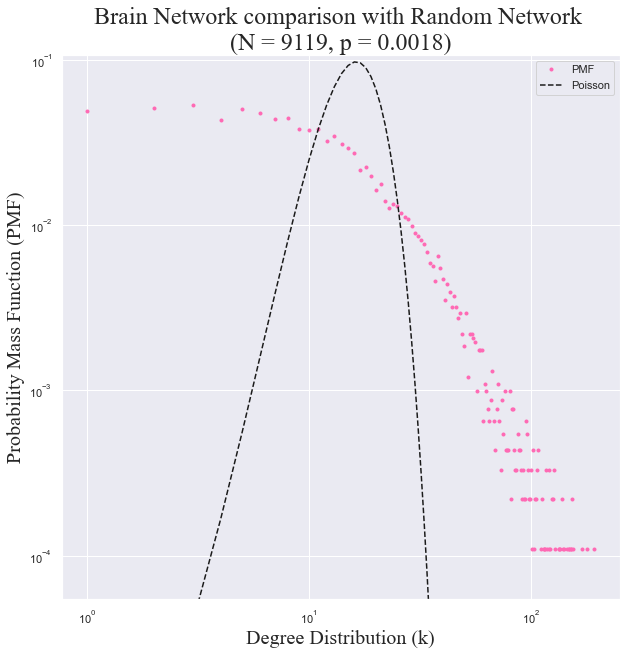

In [19]:
#Degree distribution in logaritmic-logaritmic scale

plt.figure(figsize = [10,10])
plt.plot(x0[:-1], y0, '.', label = 'PMF', color='#FF69B4')
plt.plot(x0[:-1], poisson.pmf(x0[:-1], k), 'k--', label = 'Poisson')

#Applying loh to both axis
plt.xscale('log')
plt.yscale('log')

#Looking better, like before
plt.ylim([0.5*y0[y0>0].min(),2*y0.max()])
plt.legend()


plt.title('Brain Network comparison with Random Network \n(N = %i, p = %.4f)' %(N,p), fontsize=24, fontname=font_name)
plt.xlabel('Degree Distribution (k)', fontsize = 20, fontname=font_name)
plt.ylabel('Probability Mass Function (PMF)', fontsize = 20, fontname=font_name)


In [ ]:
# Integer node degrees have a discrete PMF. Logarithmic binning creates
# a *density estimate*, not a new probability mass function.
# Divide each bin's probability mass by its width to make bins comparable.
degrees = df1["Degree"].to_numpy()
K = int(degrees.max())
edges = np.unique(np.geomspace(1, K + 1, 50).astype(int))
if edges[-1] <= K:
    edges = np.append(edges, K + 1)
counts, bin_edges = np.histogram(degrees, bins=edges)
bin_widths = np.diff(bin_edges)
density = counts / (len(degrees) * bin_widths)
valid = (counts > 0) & (bin_edges[:-1] > 0)
plt.figure(figsize=(12, 7))
plt.scatter(bin_edges[:-1][valid], density[valid], color="#FF69B4", label="Log-binned density")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Degree (k)")
plt.ylabel("Probability density (logarithmic bins)")
plt.title("Structural brain network: log-binned degree density")
plt.legend()
plt.show()


In [ ]:
# Degrees are integer-valued, so use the discrete power-law estimator.
# The fitted power law concerns only the tail k >= xmin.
Degree = df1["Degree"].to_numpy()
fit = powerlaw.Fit(Degree, discrete=True, verbose=False)
print("Power-law tail exponent alpha:", fit.alpha)
print("Tail cutoff xmin:", fit.xmin)
print("Observations in fitted tail:", int(np.count_nonzero(Degree >= fit.xmin)))


In [ ]:
# Plot the empirical degree PMF and the fitted power-law tail.
# Use powerlaw's own normalized fitted model; avoid arbitrary constants
# or an unfitted exponential extension below xmin.
fig, ax = plt.subplots(figsize=(10, 7))
powerlaw.plot_pdf(Degree, ax=ax, color="#FF69B4", marker="o",
                  linestyle="None", label="Empirical degree PMF")
fit.power_law.plot_pdf(ax=ax, color="black", linestyle="--",
                       label=f"Power-law tail (k >= {fit.xmin:g})")
ax.axvline(fit.xmin, color="gray", linestyle=":", label="xmin")
ax.set_xlabel("Degree (k)")
ax.set_ylabel("Probability mass P(k)")
ax.set_title("Degree distribution and fitted power-law tail")
ax.legend()
plt.show()


In [ ]:
# Compare POWER-LAW vs EXPONENTIAL by log-likelihood ratio.
# distribution_compare returns (R, p), NOT (KS statistic, KS p-value).
# R > 0 favors the first distribution, but a high p-value means that
# the evidence is insufficient to distinguish the models statistically.
R, p_value = fit.distribution_compare("power_law", "exponential")
print(f"Log-likelihood ratio R = {R:.4f}")
print(f"Model comparison p-value = {p_value:.4f}")
if p_value < 0.05:
    print("Statistically significant preference:",
          "power law" if R > 0 else "exponential")
else:
    print("No statistically significant preference between the two models.")

# The KS distance is an optimization diagnostic, NOT a calibrated
# goodness-of-fit p-value. A full power-law GOF test would require
# parametric bootstrap simulations of the fitted tail.
print(f"Fitted-tail KS distance D = {fit.power_law.KS():.4f}")


### Interpretation and limitations

- The likelihood-ratio comparison above is **not** a Kolmogorov–Smirnov
  goodness-of-fit test. A non-significant comparison does **not** establish
  that the network is scale-free; it simply does not distinguish the
  power-law tail from an exponential tail at the chosen significance level.
- The fitted tail begins at `xmin`; it must not be extrapolated to all degrees.
- The 50,000-node-ID restriction is not random sampling. Results describe
  this selected subgraph and may change with another selection.
- **Small-world organization has not been demonstrated here.** Evidence
  would require comparing characteristic path lengths and clustering with
  matched null networks, while accounting for possible disconnected components.
- The analysis uses a single structural connectome. Its nodes are not
  independent subject-level observations.


In [ ]:
#Plotting the clustering coefficients with the order of the nodes made a mess, just as we did before with the random one

plt.figure(figsize = [10,10])
Y= df1.Clustering #Obtaining the clustering column
plt.plot(Y, '.', color="#FF69B4", label = 'C (individual)') #Individual cluster

#Plotting
plt.plot([0,N], [p,p], '--', linewidth = 3, label = 'p = %.4f' %p , color="purple")
plt.plot([0,N], [C,C], 'k--', linewidth = 3, label = '<C> = %.4f' %C)
plt.legend()

plt.title('Clustering coefficients in the brain network, N = %i' % N, fontsize=24, fontname=font_name)
plt.xlabel('Node Number', fontsize=20, fontname=font_name)
plt.ylabel('Clustering coefficient', fontsize=20, fontname=font_name)

Text(0, 0.5, 'Clustering coefficient')

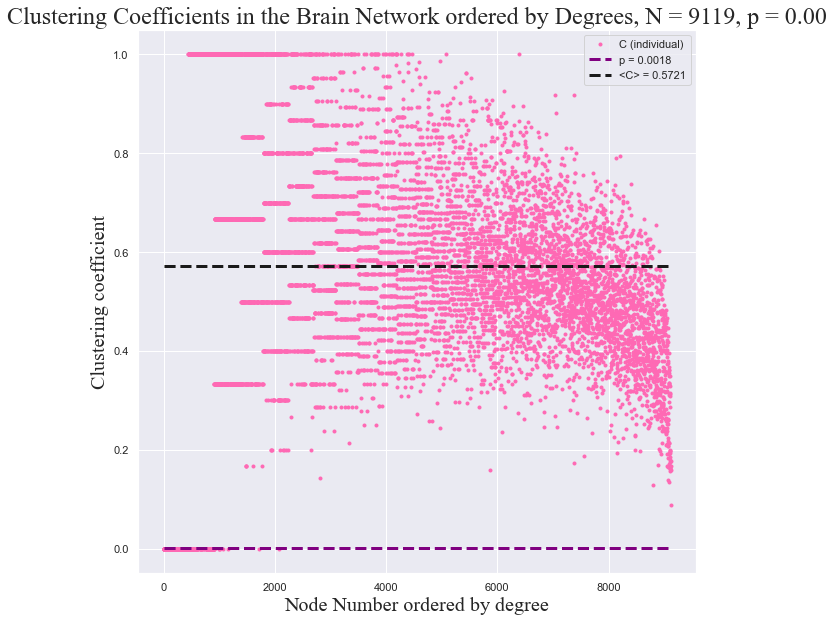

In [27]:
#Clustering coefficients ordered by degree

plt.figure(figsize = [10,10])
Y=df1.sort_values('Degree').reset_index().Clustering#.plot(style = 'b.', alpha = .4)
plt.plot(Y, '.', color="#FF69B4", label = 'C (individual)')

plt.plot([0,N], [p,p], '--', linewidth = 3, label = 'p = %.4f' %p , color="purple")
plt.plot([0,N], [C,C], 'k--', linewidth = 3, label = '<C> = %.4f' %C)

plt.legend()

plt.title('Clustering Coefficients in the Brain Network ordered by Degrees, N = %i, p = %1.2f' %(N,p), fontsize=24, fontname=font_name)
plt.xlabel('Node Number ordered by degree', fontsize=20, fontname=font_name)
plt.ylabel('Clustering coefficient', fontsize=20, fontname=font_name)

Text(0, 0.5, 'Clustering coefficient')

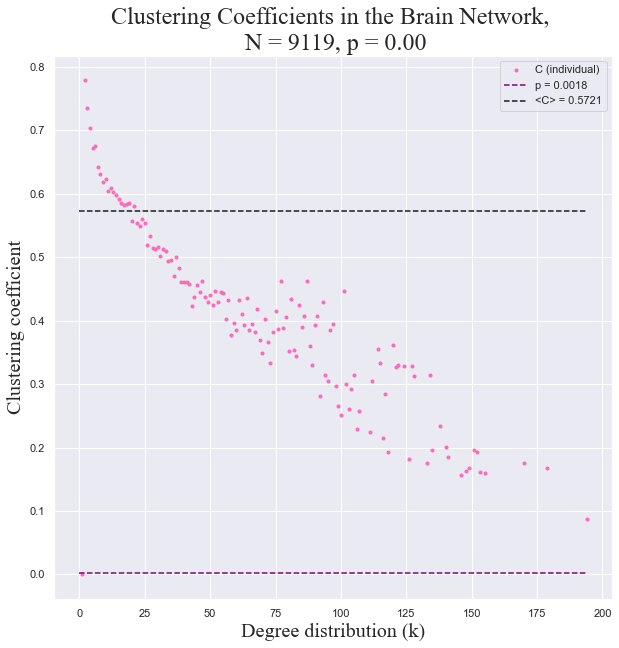

In [28]:
#Clustering coefficients vs degree distribution

X, Y = df1.groupby('Degree')['Clustering'].mean().reset_index().values.T
plt.figure(figsize=[10,10])
plt.plot(X, Y, '.', color="#FF69B4", label = 'C (individual)')

plt.plot([0,K], [p,p], '--', label = 'p = %.4f' %p, color="purple")
plt.plot([0,K], [C,C], 'k--', label = '<C> = %.4f' %C)

plt.xlabel('k', size = 20)
plt.ylabel('C(k)', size = 20)
plt.legend()

plt.title('Clustering Coefficients in the Brain Network, \n N = %i, p = %1.2f' %(N,p), fontsize=24, fontname=font_name)
plt.xlabel('Degree distribution (k)', fontsize=20, fontname=font_name)
plt.ylabel('Clustering coefficient', fontsize=20, fontname=font_name)

In [ ]:
#Obtaining the degree times the clustering to see if it give us information about the linking

#Multiplication
df1['Clustering_Degree'] = df1['Clustering'] * df1['Degree']

plt.figure(figsize = [10,10])
Y=df1.sort_values('Degree').reset_index().Clustering_Degree#.plot(style = 'b.', alpha = .4)
plt.plot(Y, '.', color="#FF69B4", label = 'C (individual)')




plt.legend()

plt.title('Clustering Coefficients times Degree in the Brain Network N = %i, p = %1.2f' %(N,p), fontsize=24, fontname=font_name)
plt.xlabel('Node Number ordered by degree', fontsize=20, fontname=font_name)
plt.ylabel('Clustering coefficient × degree', fontsize=20, fontname=font_name)